# DSC212 Research Assignment: Modularity on the Karate Club Graph

Name: Prince Punjabi  
Roll No: IMS25153  
Course: DSC212 (Mathematical Foundations for Data Science, Graph Theory Module)  
IISER Thiruvananthapuram  

---

## Introduction

This notebook is my submission for the DSC212 Graph Theory assignment on community detection using Zachary's Karate Club network. The dataset comes from Wayne Zachary's 1977 study of 34 members of a university karate club, where edges represent regular social interactions between members. After an internal disagreement between the instructor (Mr. Hi, node 0) and the club administrator (Officer, node 33), the club split into two groups.

The objective here is to use only the graph structure to find communities via recursive spectral modularity partitioning (following Newman, 2006), visualize the network after every split, compute four standard node metrics at each step, plot how those metrics change over iterations, and discuss what the results tell us about central nodes and community structure.

All cells are meant to be run in order from top to bottom.


## 1. Setup and Initial Graph

First, I import `numpy`, `networkx`, `matplotlib`, and `pandas` (just to print clean tables later), and load the Karate Club graph from NetworkX.

One small thing to be careful about: the default `nx.karate_club_graph()` stores integer edge weights on the edges. In the assignment handout, the adjacency matrix $A$ is defined as a binary matrix ($A_{ij} \in \{0, 1\}$) with $\sum_i k_i = 2m = 156$. So I pass `weight=None` when converting `G` to a NumPy array to keep it strictly unweighted.


Nodes (n): 34
Edges (m): 78
Sum of degrees: 156, 2m: 156
B is symmetric: True
Max entry of |B @ 1|: 8.88e-16


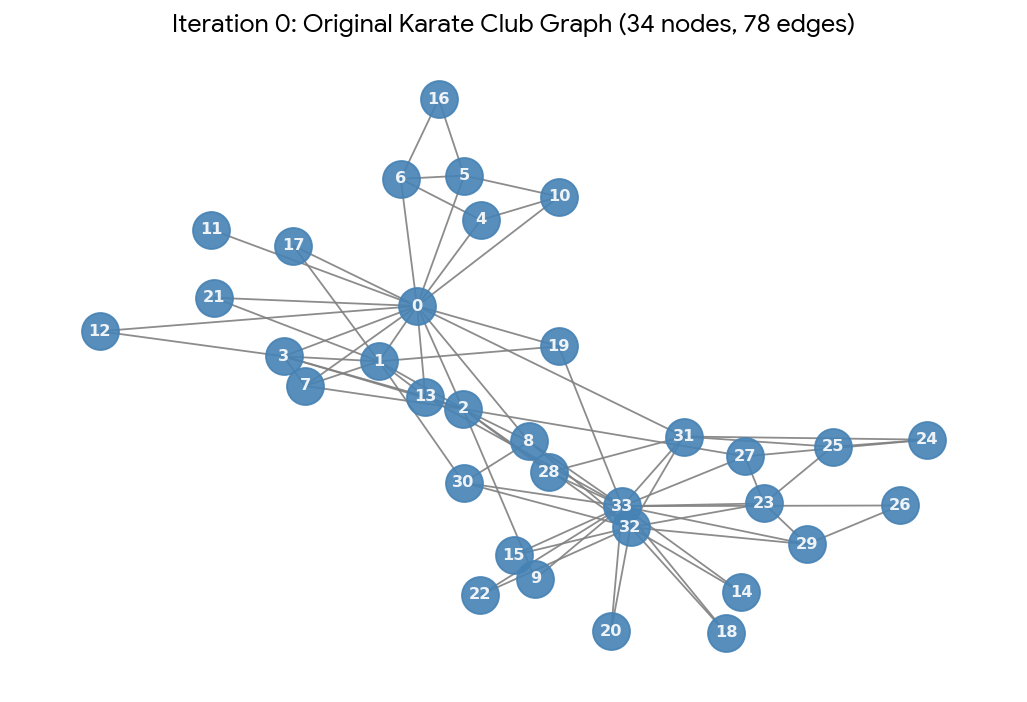

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

# load the graph
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Nodes (n): {n}")
print(f"Edges (m): {m}")

# unweighted adjacency matrix A, degree vector k, and global modularity matrix B
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# quick sanity checks from the handout propositions
print(f"Sum of degrees: {int(k.sum())}, 2m: {2 * m}")
print(f"B is symmetric: {np.allclose(B, B.T)}")
print(f"Max entry of |B @ 1|: {np.max(np.abs(B @ np.ones(n))):.2e}")

# fix one spring layout so node positions stay identical in every plot
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(8, 5.5))
nx.draw_networkx(
    G, pos,
    node_color="steelblue",
    node_size=420,
    font_color="white",
    font_size=9,
    font_weight="bold",
    edge_color="gray",
    alpha=0.9
)
plt.title("Iteration 0: Original Karate Club Graph (34 nodes, 78 edges)")
plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Recursive Spectral Modularity Partitioning

The global modularity matrix is:

$$B = A - \frac{k k^T}{2m}$$

For a two-way split encoded by $s \in \{-1, +1\}^n$, the modularity score is:

$$Q = \frac{1}{4m} s^T B s$$

Maximizing $Q$ directly over all $2^n$ sign vectors is not practical, so we relax $s$ to a unit vector ($\|s\|_2 = 1$). By the Rayleigh-Ritz theorem, the relaxed maximum is attained by the leading eigenvector $u_1$ corresponding to the largest eigenvalue $\lambda_1$ of $B$. We then round $u_1$ back to $+1$ if $(u_1)_i > 0$ and $-1$ otherwise.

### Note on restricting B to a subgraph C
When extending this to more than two communities recursively, there is an important subtlety from Newman (2006). If we just slice out the plain submatrix $B_{ij}$ for $i, j \in C$, its rows do not sum to zero anymore, so the all-ones vector is no longer guaranteed to have eigenvalue 0. When I checked that version on the Karate Club graph, it ended up isolating node 11 (which only has degree 1 and is only connected to node 0) into its own 1-node community.

Instead, Newman (2006) defines the generalized modularity matrix for a group $C$ by subtracting the row sums along the diagonal:

$$B^{(C)}_{ij} = B_{ij} - \delta_{ij} \sum_{l \in C} B_{il}, \qquad i, j \in C$$

This keeps $B^{(C)} \mathbf{1} = \mathbf{0}$ for every subgroup, makes $\Delta Q = \frac{1}{4m} s^T B^{(C)} s$ equal to the exact change in global modularity, and makes the stopping condition $\lambda_1^{(C)} \le 0$ work properly. Also, because rounding a real eigenvector to $\pm 1$ can occasionally give $\Delta Q \le 0$ even when $\lambda_1^{(C)}$ is slightly positive, I check that $\Delta Q > 0$ before accepting a split.


In [2]:
def modularity_score(communities, B, m):
    # total modularity Q = (1 / 2m) * sum over communities of B_ij
    total = 0.0
    for c in communities:
        total += B[np.ix_(c, c)].sum()
    return float(total / (2 * m))


def try_split(comm, B, m, eps=1e-10):
    if len(comm) <= 1:
        return False, comm, [], 0.0, 0.0

    # submatrix of global B for nodes in comm, with Newman's diagonal adjustment
    subB = B[np.ix_(comm, comm)].copy()
    Bg = subB - np.diag(subB.sum(axis=1))

    # eigh is for real symmetric matrices and returns eigenvalues in ascending order
    eigvals, eigvecs = np.linalg.eigh(Bg)
    lam1 = float(eigvals[-1])
    u1 = eigvecs[:, -1]

    if lam1 <= eps:
        return False, comm, [], lam1, 0.0

    # assign +1 / -1 based on the sign of the leading eigenvector
    s = np.where(u1 > 0, 1, -1)
    c_pos = [comm[i] for i in range(len(comm)) if s[i] == 1]
    c_neg = [comm[i] for i in range(len(comm)) if s[i] == -1]

    # exact change in global modularity from this discrete split
    dQ = float((s @ Bg @ s) / (4 * m))

    if len(c_pos) == 0 or len(c_neg) == 0 or dQ <= eps:
        return False, comm, [], lam1, dQ

    return True, c_pos, c_neg, lam1, dQ


def recursive_spectral_split(nodes, B, m):
    communities = [list(nodes)]
    # store the partition state at iteration 0 and after every accepted split
    history = [{
        "iteration": 0,
        "communities": [list(nodes)],
        "Q": modularity_score([nodes], B, m),
        "note": "Initial single community"
    }]

    split_num = 0
    i = 0

    while i < len(communities):
        c = communities[i]
        ok, c_pos, c_neg, lam1, dQ = try_split(c, B, m)

        if ok:
            split_num += 1
            communities = communities[:i] + [c_pos, c_neg] + communities[i + 1:]
            q_val = modularity_score(communities, B, m)
            history.append({
                "iteration": split_num,
                "communities": [list(group) for group in communities],
                "Q": q_val,
                "note": f"Split group of {len(c)} into {len(c_pos)} and {len(c_neg)} (lambda_1={lam1:.4f}, dQ=+{dQ:.4f})"
            })
            # stay at index i so we keep checking the newly created subgroup
        else:
            i += 1

    return history


history = recursive_spectral_split(nodes, B, m)

for step in history:
    print(f"Iteration {step['iteration']}: {len(step['communities'])} community(ies), Q = {step['Q']:.4f}")
    print(f"  {step['note']}")

# double check my final modularity score against NetworkX's built-in function
final_comms = history[-1]["communities"]
nx_q = nx.algorithms.community.modularity(G, final_comms, weight=None)
print(f"\nMy final Q: {history[-1]['Q']:.6f} | NetworkX modularity: {nx_q:.6f}")

print("\nFinal communities:")
for idx, comm in enumerate(final_comms, 1):
    print(f"  Community {idx} ({len(comm)} nodes): {sorted(comm)}")

Iteration 0: 1 community(ies), Q = -0.0000
  Initial single community
Iteration 1: 2 community(ies), Q = 0.3715
  Split group of 34 into 16 and 18 (lambda_1=4.9771, dQ=+0.3715)
Iteration 2: 3 community(ies), Q = 0.3727
  Split group of 16 into 7 and 9 (lambda_1=1.1785, dQ=+0.0012)
Iteration 3: 4 community(ies), Q = 0.3934
  Split group of 18 into 12 and 6 (lambda_1=0.8594, dQ=+0.0207)

My final Q: 0.393409 | NetworkX modularity: 0.393409

Final communities:
  Community 1 (7 nodes): [0, 4, 5, 6, 10, 11, 16]
  Community 2 (9 nodes): [1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 3 (12 nodes): [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  Community 4 (6 nodes): [23, 24, 25, 27, 28, 31]


My modularity calculation matches NetworkX's `modularity()` function to 6 decimal places (`0.393409`), which confirms the implementation is working as intended.

Next, I check how closely the very first split (Iteration 1) matches the real-world split recorded by Zachary.


In [3]:
# compare Iteration 1 against Zachary's ground truth
mr_hi = {u for u, d in G.nodes(data=True) if d["club"] == "Mr. Hi"}
officer = {u for u, d in G.nodes(data=True) if d["club"] == "Officer"}

g1 = set(history[1]["communities"][0])
g2 = set(history[1]["communities"][1])

# match whichever label assignment aligns best
if len(g1 & mr_hi) + len(g2 & officer) >= len(g1 & officer) + len(g2 & mr_hi):
    pred_hi, pred_off = g1, g2
else:
    pred_hi, pred_off = g2, g1

correct = len(pred_hi & mr_hi) + len(pred_off & officer)
mismatched = (pred_hi ^ mr_hi) | (pred_off ^ officer)
print(f"Agreement with ground truth at Iteration 1: {correct}/{n} ({100 * correct / n:.2f}%)")
print(f"Mismatched node(s): {sorted(mismatched)}")

Agreement with ground truth at Iteration 1: 33/34 (97.06%)
Mismatched node(s): [8]


Only node 8 differs from the real split (33 out of 34 nodes match, or 97.06%). In Zachary's original paper, node 8 was actually a weak supporter of Mr. Hi who happened to have slightly more social ties on the Officer's side, so purely structural methods almost always place node 8 with the Officer.

## 3. Visualizing the Graph After Each Split

Now I draw the graph after each split using the same fixed spring layout (`pos`). Each community gets its own color. Edges inside a community are drawn as solid dark lines, while edges that cross between communities are drawn as light dashed lines so it is easy to see where the cuts happen.


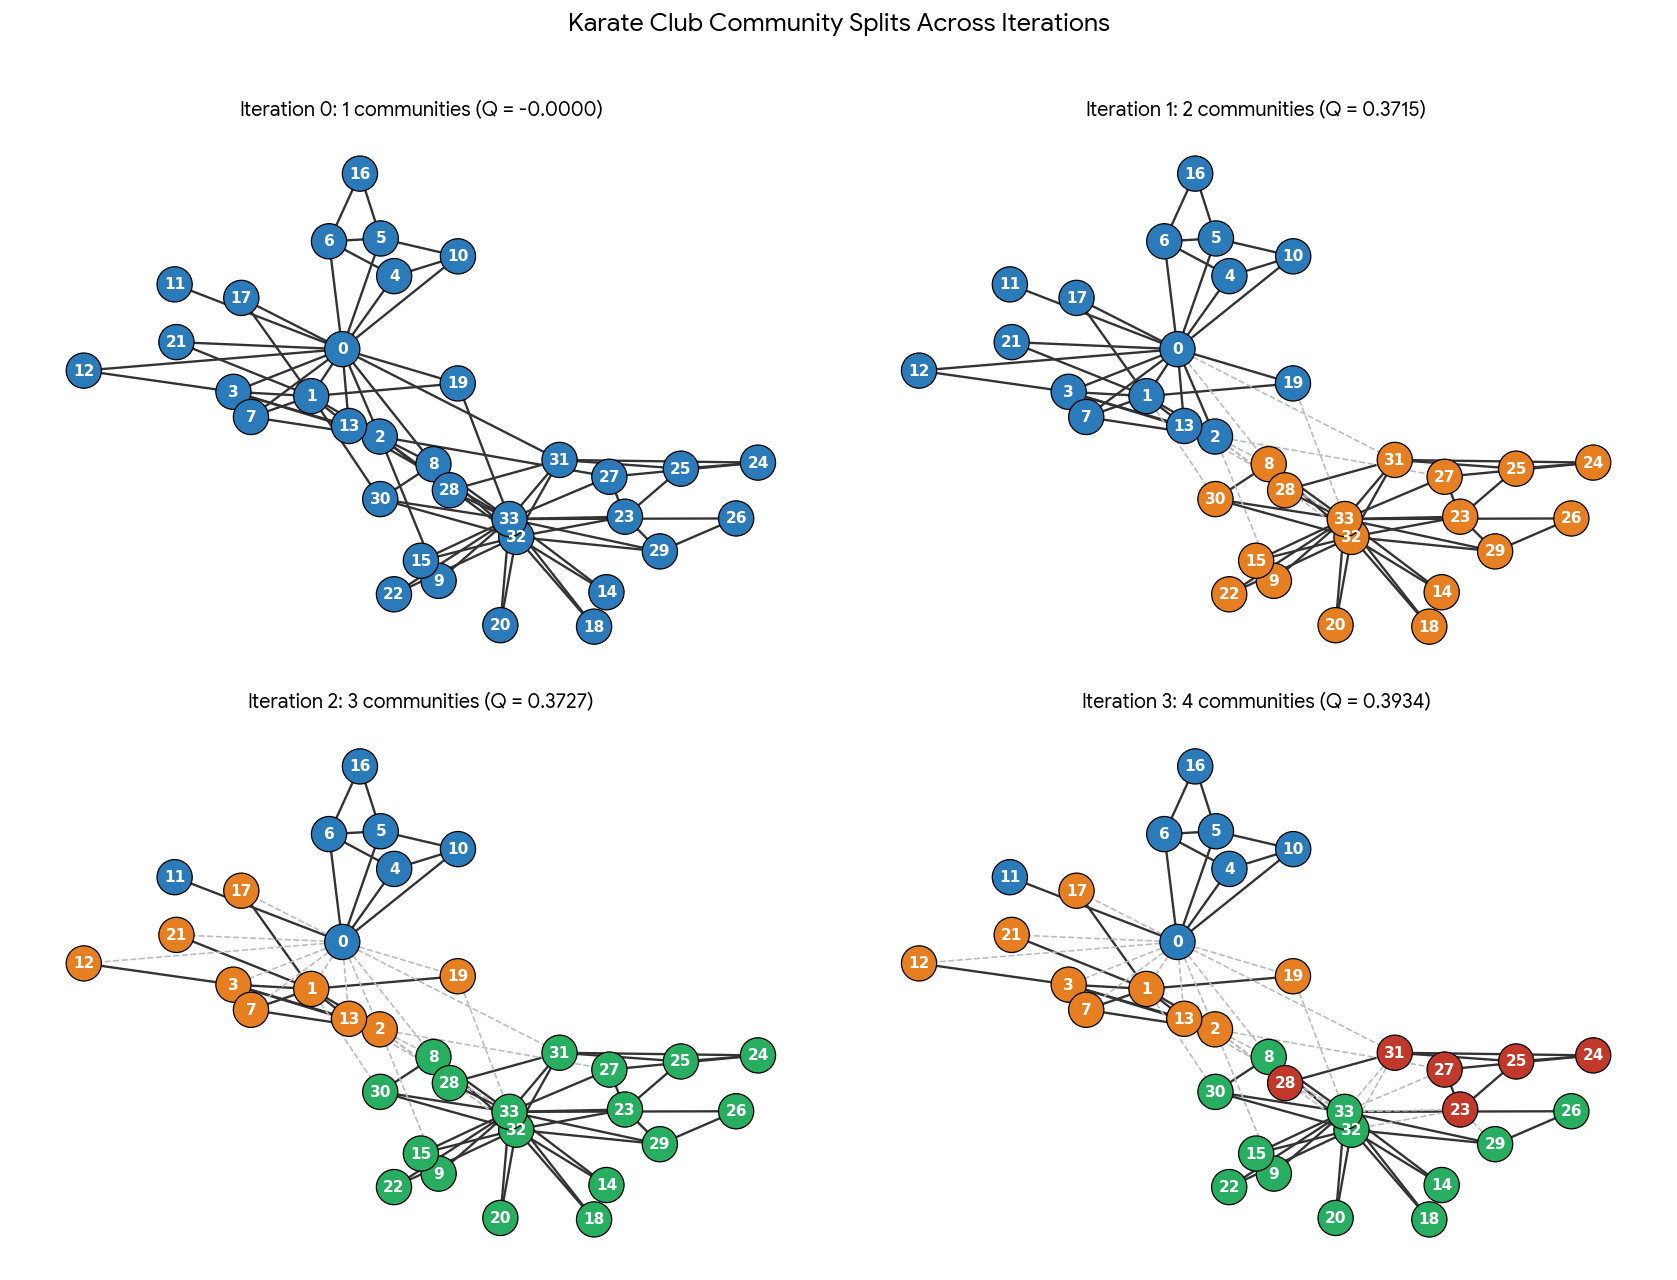

In [4]:
colors_list = ["#2b7bba", "#e67e22", "#27ae60", "#c0392b", "#8e44ad", "#16a085"]

def make_node_comm_map(communities):
    cmap = {}
    for cid, comm in enumerate(communities):
        for u in comm:
            cmap[u] = cid
    return cmap

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for ax, step in zip(axes, history):
    it = step["iteration"]
    comms = step["communities"]
    q_val = step["Q"]
    cmap = make_node_comm_map(comms)

    node_colors = [colors_list[cmap[u] % len(colors_list)] for u in nodes]
    inside_edges = [(u, v) for u, v in G.edges() if cmap[u] == cmap[v]]
    cut_edges = [(u, v) for u, v in G.edges() if cmap[u] != cmap[v]]

    nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodes, node_color=node_colors,
                           node_size=380, edgecolors="black", linewidths=0.7)
    nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_size=8.5, font_weight="bold")
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=inside_edges, edge_color="#333333", width=1.3)
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=cut_edges, edge_color="#bbbbbb", style="dashed", width=0.9)

    ax.set_title(f"Iteration {it}: {len(comms)} communities (Q = {q_val:.4f})", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("Karate Club Community Splits Across Iterations", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

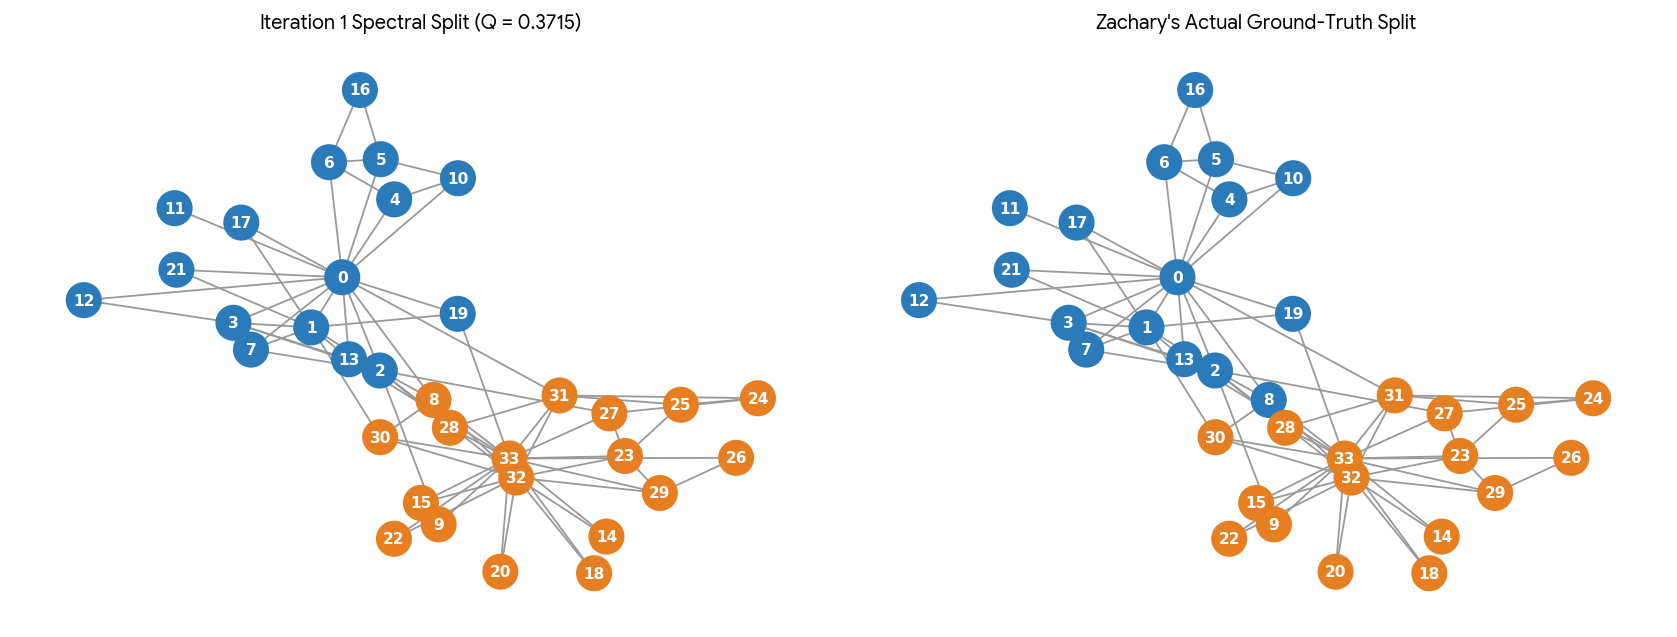

In [5]:
# side by side view of Iteration 1 vs Zachary's actual split
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cmap_1 = make_node_comm_map(history[1]["communities"])
c1 = [colors_list[cmap_1[u]] for u in nodes]
nx.draw_networkx(G, pos, ax=ax1, nodelist=nodes, node_color=c1, node_size=360,
                 font_color="white", font_size=8.5, font_weight="bold", edge_color="#999999")
ax1.set_title(f"Iteration 1 Spectral Split (Q = {history[1]['Q']:.4f})", fontsize=11, fontweight="bold")
ax1.axis("off")

gt_colors = [colors_list[0] if G.nodes[u]["club"] == "Mr. Hi" else colors_list[1] for u in nodes]
nx.draw_networkx(G, pos, ax=ax2, nodelist=nodes, node_color=gt_colors, node_size=360,
                 font_color="white", font_size=8.5, font_weight="bold", edge_color="#999999")
ax2.set_title("Zachary's Actual Ground-Truth Split", fontsize=11, fontweight="bold")
ax2.axis("off")

plt.tight_layout()
plt.show()

## 4. Computing Node Metrics After Each Split

If we computed NetworkX centrality metrics on the untouched original graph after each split, we would just get the exact same numbers every time. To actually see how splitting the network into communities affects node importance, at each iteration I build a copy of the graph that keeps all 34 nodes but removes the inter-community edges (so only within-community edges remain).

On this graph at each iteration (Iteration 0 is the full graph with all 78 edges), I compute:
1. Degree centrality: `nx.degree_centrality`
2. Betweenness centrality: `nx.betweenness_centrality`
3. Closeness centrality: `nx.closeness_centrality` (NetworkX automatically scales closeness by component size for disconnected graphs)
4. Clustering coefficient: `nx.clustering`

All four metrics are stored in dictionaries keyed by iteration number.


In [6]:
degree_by_iter = {}
betweenness_by_iter = {}
closeness_by_iter = {}
clustering_by_iter = {}

for step in history:
    it = step["iteration"]
    cmap = make_node_comm_map(step["communities"])

    # keep all 34 nodes, keep only edges inside the same community
    G_split = nx.Graph()
    G_split.add_nodes_from(nodes)
    for u, v in G.edges():
        if cmap[u] == cmap[v]:
            G_split.add_edge(u, v)

    degree_by_iter[it] = nx.degree_centrality(G_split)
    betweenness_by_iter[it] = nx.betweenness_centrality(G_split)
    closeness_by_iter[it] = nx.closeness_centrality(G_split)
    clustering_by_iter[it] = nx.clustering(G_split)

all_metrics = {
    "Degree Centrality": degree_by_iter,
    "Betweenness Centrality": betweenness_by_iter,
    "Closeness Centrality": closeness_by_iter,
    "Clustering Coefficient": clustering_by_iter,
}

# print a compact table of top 5 nodes at each iteration for every metric
for name, m_dict in all_metrics.items():
    print(f"Top 5 nodes for {name}:")
    rows = []
    for it, vals in m_dict.items():
        top5 = sorted(vals.items(), key=lambda x: (-x[1], x[0]))[:5]
        rows.append({
            "Iteration": it,
            "Rank 1": f"{top5[0][0]} ({top5[0][1]:.3f})",
            "Rank 2": f"{top5[1][0]} ({top5[1][1]:.3f})",
            "Rank 3": f"{top5[2][0]} ({top5[2][1]:.3f})",
            "Rank 4": f"{top5[3][0]} ({top5[3][1]:.3f})",
            "Rank 5": f"{top5[4][0]} ({top5[4][1]:.3f})",
        })
    print(pd.DataFrame(rows).to_string(index=False))
    print()

Top 5 nodes for Degree Centrality:
 Iteration     Rank 1     Rank 2     Rank 3    Rank 4    Rank 5
         0 33 (0.515)  0 (0.485) 32 (0.364) 2 (0.303) 1 (0.273)
         1 33 (0.455)  0 (0.424) 32 (0.333) 1 (0.242) 3 (0.182)
         2 33 (0.455) 32 (0.333)  1 (0.212) 0 (0.152) 3 (0.152)
         3 33 (0.333) 32 (0.273)  1 (0.212) 0 (0.152) 3 (0.152)

Top 5 nodes for Betweenness Centrality:
 Iteration     Rank 1     Rank 2     Rank 3     Rank 4     Rank 5
         0  0 (0.438) 33 (0.304) 32 (0.145)  2 (0.144) 31 (0.138)
         1 33 (0.147)  0 (0.137) 32 (0.052) 31 (0.029) 23 (0.016)
         2 33 (0.147) 32 (0.052)  1 (0.035) 31 (0.029) 23 (0.016)
         3 33 (0.059)  1 (0.035) 32 (0.026)  3 (0.014)  0 (0.011)

Top 5 nodes for Closeness Centrality:
 Iteration     Rank 1     Rank 2     Rank 3     Rank 4     Rank 5
         0  0 (0.569)  2 (0.559) 33 (0.550) 31 (0.541)  8 (0.516)
         1 33 (0.461)  0 (0.426) 32 (0.381) 23 (0.302) 31 (0.302)
         2 33 (0.461) 32 (0.381) 23 (

## 5. Plotting Metric Evolution Across Iterations

To show how every node behaves across Iterations 0 to 3:
- First, I plot line graphs for all 34 nodes. Putting 34 separate colors in one legend gets unreadable very fast, so I draw the rest of the nodes as thin light-grey lines and highlight the main hub/bridge nodes (`0, 33, 32, 1, 2, 3, 31, 5`) with distinct colors and markers.
- Second, I plot a 2x2 grid of heatmaps so that the exact evolution of every single node from 0 to 33 can be read clearly without overlapping lines.


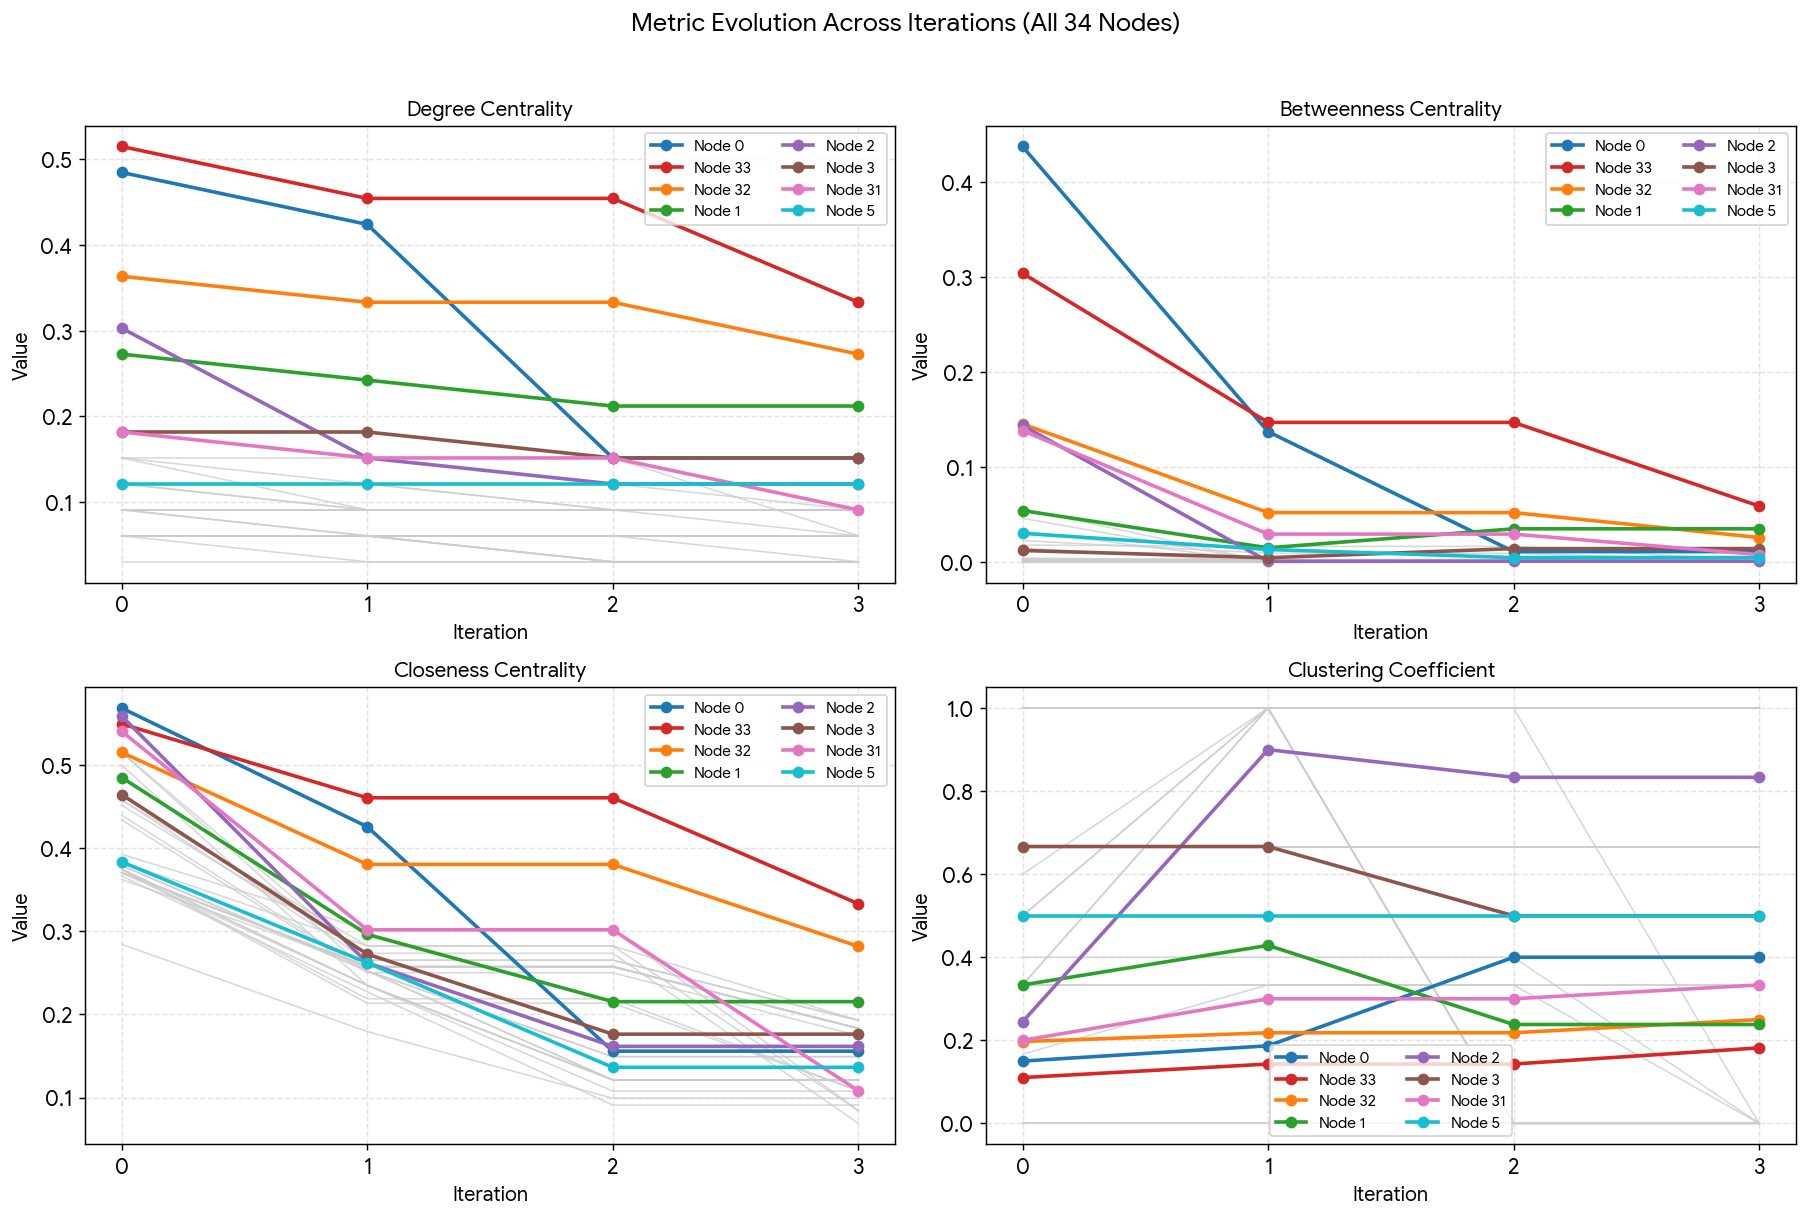

In [7]:
iters = [step["iteration"] for step in history]
key_nodes = [0, 33, 32, 1, 2, 3, 31, 5]
key_colors = {
    0: "#1f77b4",
    33: "#d62728",
    32: "#ff7f0e",
    1: "#2ca02c",
    2: "#9467bd",
    3: "#8c564b",
    31: "#e377c2",
    5: "#17becf",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
axes = axes.flatten()

for ax, (name, m_dict) in zip(axes, all_metrics.items()):
    # background trajectories for all other nodes
    for u in nodes:
        if u not in key_nodes:
            y = [m_dict[it][u] for it in iters]
            ax.plot(iters, y, color="#cccccc", linewidth=0.9, alpha=0.75)

    # highlighted nodes
    for u in key_nodes:
        y = [m_dict[it][u] for it in iters]
        ax.plot(iters, y, color=key_colors[u], marker="o", linewidth=2.0, markersize=5.5, label=f"Node {u}")

    ax.set_title(name, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Value")
    ax.set_xticks(iters)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(fontsize=8.5, ncol=2, loc="best")

plt.suptitle("Metric Evolution Across Iterations (All 34 Nodes)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

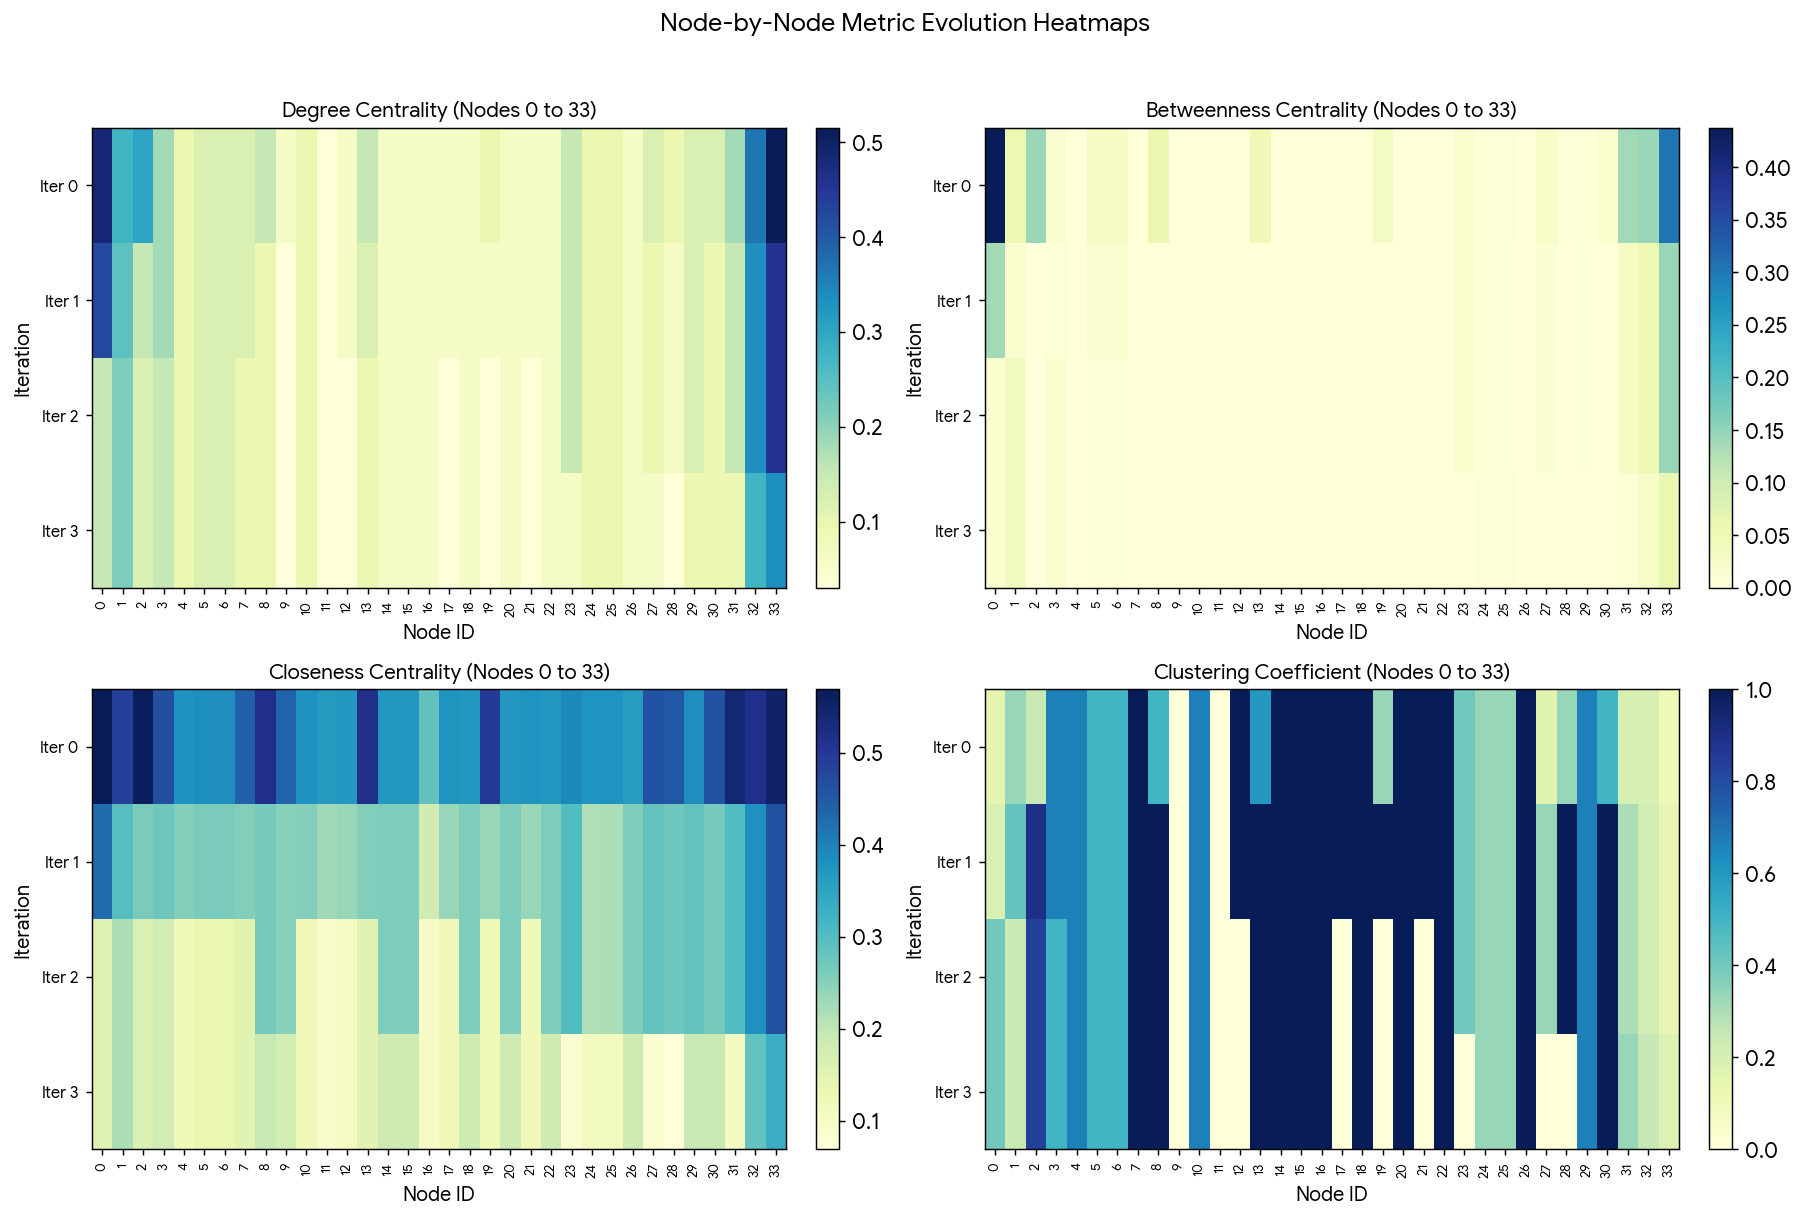

In [8]:
# heatmaps so every individual node (0 to 33) is clearly visible
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
axes = axes.flatten()

for ax, (name, m_dict) in zip(axes, all_metrics.items()):
    data = np.array([[m_dict[it][u] for u in nodes] for it in iters])
    im = ax.imshow(data, aspect="auto", cmap="YlGnBu")
    ax.set_title(f"{name} (Nodes 0 to 33)", fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Node ID")
    ax.set_ylabel("Iteration")
    ax.set_xticks(range(n))
    ax.set_xticklabels(nodes, fontsize=7.5, rotation=90)
    ax.set_yticks(range(len(iters)))
    ax.set_yticklabels([f"Iter {it}" for it in iters], fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Node-by-Node Metric Evolution Heatmaps", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 6. Discussion

### Which nodes remain central across splits?
- **Node 33 (Officer)** is the single most consistent central node in the entire graph. It stays #1 in degree centrality across all four iterations (from 0.515 down to 0.333), stays #1 in betweenness from Iteration 1 onward, and stays #1 in closeness from Iteration 1 onward.
- **Node 32** (closely tied to Node 33) also stays in the top 3 for degree, betweenness, and closeness through every single split.
- **Node 0 (Mr. Hi)** starts at the very top in betweenness (0.438) and closeness (0.569) and second in degree (0.485). After Iteration 1, it still leads its half of the club. However, at Iteration 2, Mr. Hi's faction splits into two subgroups: `[0, 4, 5, 6, 10, 11, 16]` and `[1, 2, 3, 7, 12, 13, 17, 19, 21]`. Because Node 0 loses its direct links to nodes 1, 2, 3, 7, 13, 17, 19, and 21 in that split, its degree drops sharply from 0.424 to 0.152, though it still stays in the top 5 overall and remains the main hub of its 7-node subgroup.
- **Node 1** becomes the main local hub of the 9-node subgroup after Iteration 2, jumping to #3 in degree (0.212) and #2 in betweenness (0.035) by Iteration 3.

### How does community structure influence the metrics?
1. **Degree centrality decreases monotonically** for nodes that sit on community borders, since cutting inter-community edges removes their cross-group connections. For example, **Node 2** starts at 4th highest degree (0.303) because it connects heavily to both Mr. Hi's side and the Officer's side, but loses half its ties after the splits. Meanwhile, nodes sitting strictly inside one tightly knit subgroup barely lose any degree.
2. **Betweenness centrality reacts the most strongly to splits.** In the original graph, bridge nodes like **Node 0** (0.438), **Node 2** (0.144), and **Node 31** (0.138) have high betweenness because shortest paths between the two factions have to pass through them. As soon as cross-community edges are cut at Iteration 1, all cross-faction shortest paths vanish, and Node 2's betweenness collapses from 0.144 down to almost zero. After the final split, only within-community hubs (Nodes 33, 1, 32, 3, 0) hold noticeable betweenness.
3. **Closeness centrality drops across the whole graph** after each split. Because the graph breaks into smaller disconnected components, each node can reach a smaller fraction of the 34 total nodes, so NetworkX's component-scaled closeness score drops roughly in proportion to the size of each node's community. That is why the largest final community (the 12-node group around Nodes 33 and 32) ends up with the highest closeness scores.
4. **Clustering coefficient behaves differently because it is local.** Cutting bridge edges removes links between neighbors that were not connected to each other anyway. As a result, nodes inside dense local triangles (such as Nodes 7, 8, 13, 14, 15, 16, 18, 20, 22) keep a clustering coefficient of 1.0, and some border nodes (like **Node 8**, which goes from 0.500 at Iteration 0 to 1.000 at Iteration 1) actually see their clustering go *up* once their outside links are removed.

---

## References
1. Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences (PNAS)*, 103(23), 8577-8582.
2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452-473.
3. DSC212 Graph Theory Module Handout: Modularity on the Karate Club Graph.
